In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, chi2


In [9]:
# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Select relevant features and drop rows with missing values
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
df.dropna(inplace=True)

In [10]:
# Encode categorical variables
df['Sex'] = LabelEncoder().fit_transform(df['Sex'])
df['Embarked'] = LabelEncoder().fit_transform(df['Embarked'])
X = df.drop('Survived', axis=1)
y = df['Survived']
feature_names = X.columns

In [11]:
feature_names

Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'], dtype='object')

In [12]:
# Sử dụng phương pháp Filter
# Filter Method: ANOVA F-Test

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X, y)
scores = selector.scores_

ranked = sorted(zip(feature_names, scores), key=lambda x: x[1], reverse=True)

print("Filter Method - Feature Ranking:")
print("= = = = = = = = = = = = = = = == = = = == ")
for name, score in ranked:
    print(f"{name}: {score:.2f}")

Filter Method - Feature Ranking:
= = = = = = = = = = = = = = = == = = = == 
Sex: 287.35
Pclass: 103.35
Fare: 54.11
Embarked: 24.32
Parch: 6.50
Age: 4.86
SibSp: 0.17


In [13]:
# Sử dụng phương pháp Filter với ChiSqure
# score_func với một số phương pháp như: f_classif (ANOVA F-Test ), mutual_info_classif (Mutual Information), chi2(Chi-squared), f_regression (F-Value)

selector = SelectKBest(score_func=chi2, k=10)
selector.fit(X, y)
scores = selector.scores_

ranked = sorted(zip(feature_names, scores), key=lambda x: x[1], reverse=True)

print("Filter Method - Feature Ranking:")
print("= = = = = = = = = = = = = = = == = = = == ")
for name, score in ranked:
    print(f"{name}: {score:.2f}")

Filter Method - Feature Ranking:
= = = = = = = = = = = = = = = == = = = == 
Fare: 4081.68
Sex: 74.62
Age: 34.25
Pclass: 28.24
Parch: 10.88
Embarked: 8.96
SibSp: 0.29


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=10 is greater than n_features=7. All the features will be returned.
  warnings.warn(


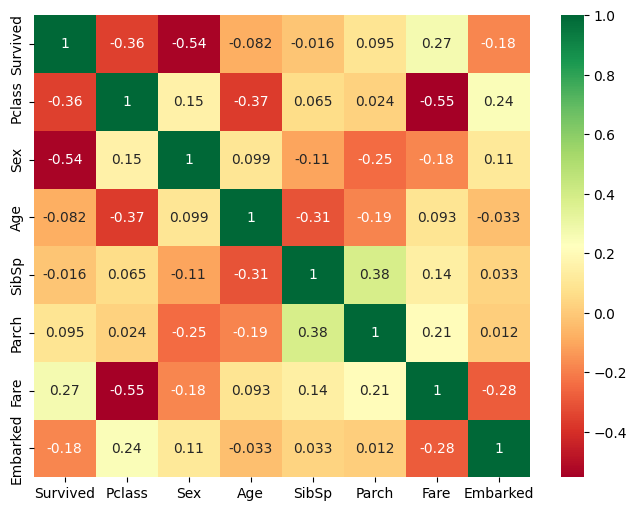

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

#get correlations of each features in dataset
corrmat = df.corr()
top_corr_features = corrmat.index

plt.figure(figsize=(8,6))

#plot heat map
g=sns.heatmap(df[top_corr_features].corr(),annot=True,cmap="RdYlGn")